In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from pathlib import Path
from pairs_backtest_engine import backtest_pair

prices = pd.read_csv("clean_prices.csv", index_col=0, parse_dates=True).sort_index()
prices = prices[["AVGO", "FIX"]].dropna()

model_train = prices.loc["2020-03-19":"2022-12-31"].copy()
validation = prices.loc["2023-01-01":"2024-12-31"].copy()

assert len(model_train) >= 252
assert len(validation) >= 100
assert model_train.index.max() < validation.index.min()

print("Training:", model_train.index.min().date(), "to", model_train.index.max().date(), len(model_train))
print("Validation:", validation.index.min().date(), "to", validation.index.max().date(), len(validation))

Training: 2020-03-19 to 2022-12-30 703
Validation: 2023-01-03 to 2024-12-31 502


In [2]:
baseline_config = {
    "ticker_a": "AVGO",
    "ticker_b": "FIX",
    "p_value_threshold": 0.05,
    "fdr_threshold": 0.05,
    "entry_z": 2.0,
    "exit_z": 0.0,
    "hedge_lookback": None,
    "stop_loss_z": None,
    "max_holding_days": None,
    "transaction_cost": 0.001,
    "slippage": 0.0,
    "execution_lag": 1,
    "trading_days": 252
}

baseline_config

{'ticker_a': 'AVGO',
 'ticker_b': 'FIX',
 'p_value_threshold': 0.05,
 'fdr_threshold': 0.05,
 'entry_z': 2.0,
 'exit_z': 0.0,
 'hedge_lookback': None,
 'stop_loss_z': None,
 'max_holding_days': None,
 'transaction_cost': 0.001,
 'slippage': 0.0,
 'execution_lag': 1,
 'trading_days': 252}

,Pair,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Holding Days,Avg Trade Return (%),Turnover,Net P&L
0,AVGO-FIX,152.849,59.455,39.098,1.381,-24.84,6,83.333,60.833,11.778,31.72,142.713


,Entry Date,Exit Date,Direction,Hedge Ratio,Holding Days,Gross P&L,Transaction Cost,Net P&L,Trade Return (%),Exit Reason
0,2023-02-27,2023-05-26,1,0.352893,63,20.958243,0.236929,20.721314,19.406324,Mean reversion
1,2023-06-15,2023-09-13,-1,0.352893,61,11.581071,0.289282,11.291789,7.989309,Mean reversion
2,2023-10-13,2024-03-18,-1,0.352893,106,18.021646,0.369607,17.652038,12.522112,Mean reversion
3,2024-06-07,2024-11-12,-1,0.352893,109,19.756780,0.579650,19.177130,7.856051,Mean reversion
4,2024-11-19,2024-12-16,1,0.352893,18,87.226288,0.737164,86.489124,26.289615,Mean reversion
5,2024-12-18,2024-12-31,-1,0.352893,8,-11.869348,0.749054,-12.618402,-3.394135,End of backtest


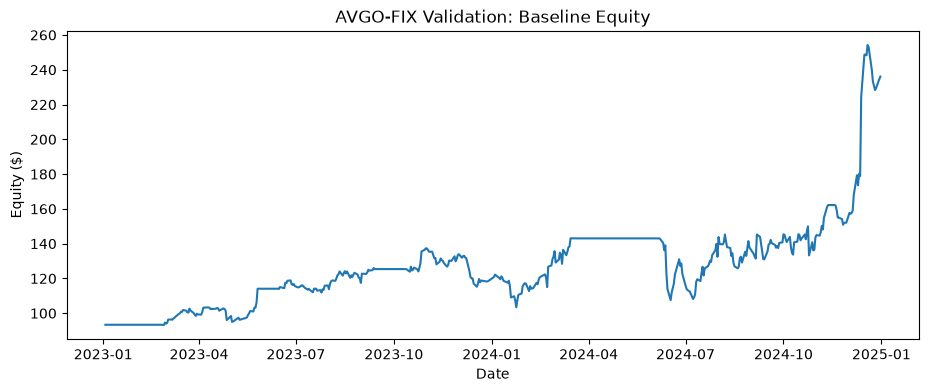

In [3]:
baseline = backtest_pair(baseline_config, model_train, validation)

display(pd.DataFrame([baseline["metrics"]]).round(3))
display(baseline["trade_log"])

plt.figure(figsize=(11, 4))
plt.plot(baseline["daily_results"].index, baseline["daily_results"]["Equity"])
plt.title("AVGO-FIX Validation: Baseline Equity")
plt.xlabel("Date")
plt.ylabel("Equity ($)")
plt.show()

In [4]:
stop_values = [None, 3.0, 3.5, 4.0]
holding_values = [None, 60, 120, 180]

experiments = {}
rows = []

for stop, holding in product(stop_values, holding_values):
    config = baseline_config.copy()
    config["stop_loss_z"] = stop
    config["max_holding_days"] = holding

    result = backtest_pair(config, model_train, validation)
    experiments[(stop, holding)] = result

    row = result["metrics"].copy()
    row["Stop Loss Z"] = "None" if stop is None else stop
    row["Max Holding"] = "None" if holding is None else holding
    rows.append(row)

optimization_table = pd.DataFrame(rows)
optimization_table = optimization_table.sort_values(
    ["Max Drawdown (%)", "Total Return (%)"], ascending=[False, False]
).reset_index(drop=True)

display(optimization_table.round(3))

,Pair,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Holding Days,Avg Trade Return (%),Turnover,Net P&L,Stop Loss Z,Max Holding
0,AVGO-FIX,25.351,12.036,13.595,0.902,-10.594,5,60.000,25.400,3.376,26.119,23.670,3.5,60
1,AVGO-FIX,22.336,10.672,13.652,0.809,-13.046,5,60.000,25.200,3.146,26.016,20.855,3.0,60
2,AVGO-FIX,30.713,14.422,16.269,0.907,-21.624,6,50.000,29.000,3.824,29.698,28.677,3.5,None
3,AVGO-FIX,30.713,14.422,16.269,0.907,-21.624,6,50.000,29.000,3.824,29.698,28.677,3.5,120
4,AVGO-FIX,30.713,14.422,16.269,0.907,-21.624,6,50.000,29.000,3.824,29.698,28.677,3.5,180
5,AVGO-FIX,27.792,13.128,16.307,0.836,-23.610,6,50.000,28.667,3.642,29.561,25.949,3.0,None
6,AVGO-FIX,27.792,13.128,16.307,0.836,-23.610,6,50.000,28.667,3.642,29.561,25.949,3.0,120
7,AVGO-FIX,27.792,13.128,16.307,0.836,-23.610,6,50.000,28.667,3.642,29.561,25.949,3.0,180
8,AVGO-FIX,152.849,59.455,39.098,1.381,-24.840,6,83.333,60.833,11.778,31.720,142.713,None,None
9,AVGO-FIX,152.849,59.455,39.098,1.381,-24.840,6,83.333,60.833,11.778,31.720,142.713,None,120


In [5]:
diagnostic = experiments[(3.0, None)]
print("Stop-loss 3.0 trade count:", len(diagnostic["trade_log"]))
print("Exit reasons:")
print(diagnostic["trade_log"]["Exit Reason"].value_counts())
print("Re-entry unlocks:", len(diagnostic["reentry_unlock_dates"]))
display(diagnostic["trade_log"].head(12))


Stop-loss 3.0 trade count: 6
Exit reasons:
Exit Reason
Stop loss         4
Mean reversion    2
Name: count, dtype: int64
Re-entry unlocks: 3


,Entry Date,Exit Date,Direction,Hedge Ratio,Holding Days,Gross P&L,Transaction Cost,Net P&L,Trade Return (%),Exit Reason
0,2023-02-27,2023-05-26,1,0.352893,63,20.958243,0.236929,20.721314,19.406324,Mean reversion
1,2023-06-15,2023-09-13,-1,0.352893,61,11.581071,0.289282,11.291789,7.989309,Mean reversion
2,2023-10-13,2023-12-13,-1,0.352893,42,-5.188319,0.316728,-5.505047,-3.905204,Stop loss
3,2024-06-07,2024-06-11,-1,0.352893,2,-6.586869,0.492250,-7.079119,-2.900012,Stop loss
4,2024-11-19,2024-11-21,1,0.352893,2,-6.838095,0.662038,-7.500132,-2.279773,Stop loss
5,2024-12-17,2024-12-19,-1,0.352893,2,14.783304,0.762886,14.020418,3.544192,Stop loss


In [6]:
base_config = {
    "ticker_a": "AVGO",
    "ticker_b": "FIX",
    "entry_z": 2.0,
    "exit_z": 0.0,
    "hedge_lookback": None,
    "stop_loss_z": None,
    "max_holding_days": None,
    "transaction_cost": 0.001,
    "slippage": 0.0,
    "execution_lag": 1,
    "trading_days": 252
}

stop_values = [None, 3.0, 3.5, 4.0]
holding_values = [None, 60, 120, 180]
years = [2023, 2024, 2025, 2026]
parameter_grid = list(product(stop_values, holding_values))

print("Parameter combinations:", len(parameter_grid))
print("Rolling windows:", len(years))
print("Total backtests:", len(parameter_grid) * len(years))

Parameter combinations: 16
Rolling windows: 4
Total backtests: 64


In [7]:
experiments = {}
rows = []

for year in years:
    training = prices.loc[f"{year-3}-01-01":f"{year-1}-12-31"].copy()
    testing = prices.loc[f"{year}-01-01":f"{year}-12-31"].copy()

    if len(training) < 252 or len(testing) < 3:
        raise ValueError(f"Insufficient observations for {year}: {len(training)} train, {len(testing)} test")

    print(f"{year}: train={len(training)} days, test={len(testing)} days", flush=True)

    for stop, holding in parameter_grid:
        config = base_config.copy()
        config["stop_loss_z"] = stop
        config["max_holding_days"] = holding

        result = backtest_pair(config, training, testing)
        experiments[(year, stop, holding)] = result

        row = result["metrics"].copy()
        row["Year"] = year
        row["Stop Loss Z"] = stop
        row["Max Holding"] = holding
        row["Config"] = f"Stop={stop}, Hold={holding}"
        rows.append(row)

print("Completed:", len(experiments), "backtests")
wf_results = pd.DataFrame(rows)
assert len(wf_results) == 64
assert all("reentry_unlock_dates" in r for r in experiments.values())
display(wf_results[["Year", "Config", "Total Return (%)", "Sharpe", "Max Drawdown (%)", "Trades"]].round(3).head(20))

2023: train=703 days, test=250 days
2024: train=753 days, test=252 days
2025: train=753 days, test=250 days
2026: train=752 days, test=219 days
Completed: 64 backtests


,Year,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades
0,2023,"Stop=None, Hold=None",26.856,1.278,-16.082,3
1,2023,"Stop=None, Hold=60",22.934,1.470,-8.054,2
2,2023,"Stop=None, Hold=120",26.856,1.278,-16.082,3
3,2023,"Stop=None, Hold=180",26.856,1.278,-16.082,3
4,2023,"Stop=3.0, Hold=None",28.391,1.365,-12.705,3
5,2023,"Stop=3.0, Hold=60",22.934,1.470,-8.054,2
6,2023,"Stop=3.0, Hold=120",28.391,1.365,-12.705,3
7,2023,"Stop=3.0, Hold=180",28.391,1.365,-12.705,3
8,2023,"Stop=3.5, Hold=None",28.297,1.362,-12.769,3
9,2023,"Stop=3.5, Hold=60",22.934,1.470,-8.054,2


In [8]:
for year in years:
    year_table = wf_results.loc[
        wf_results["Year"] == year,
        ["Config", "Total Return (%)", "Sharpe", "Max Drawdown (%)", "Trades", "Avg Holding Days"]
    ].sort_values("Max Drawdown (%)", ascending=False)
    print(f"\n{year} (sorted by Max Drawdown, closest to zero first)")
    display(year_table.round(3).reset_index(drop=True))


2023 (sorted by Max Drawdown, closest to zero first)


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Avg Holding Days
0,"Stop=None, Hold=60",22.934,1.470,-8.054,2,60.000
1,"Stop=3.0, Hold=60",22.934,1.470,-8.054,2,60.000
2,"Stop=3.5, Hold=60",22.934,1.470,-8.054,2,60.000
3,"Stop=4.0, Hold=60",22.934,1.470,-8.054,2,60.000
4,"Stop=3.0, Hold=None",28.391,1.365,-12.705,3,55.333
5,"Stop=3.0, Hold=120",28.391,1.365,-12.705,3,55.333
6,"Stop=3.0, Hold=180",28.391,1.365,-12.705,3,55.333
7,"Stop=3.5, Hold=None",28.297,1.362,-12.769,3,55.667
8,"Stop=3.5, Hold=120",28.297,1.362,-12.769,3,55.667
9,"Stop=3.5, Hold=180",28.297,1.362,-12.769,3,55.667



2024 (sorted by Max Drawdown, closest to zero first)


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Avg Holding Days
0,"Stop=None, Hold=None",65.154,1.662,-14.446,6,29.667
1,"Stop=None, Hold=60",60.086,1.579,-14.446,6,24.167
2,"Stop=None, Hold=120",65.154,1.662,-14.446,6,29.667
3,"Stop=None, Hold=180",65.154,1.662,-14.446,6,29.667
4,"Stop=3.0, Hold=None",-0.535,0.045,-16.097,6,5.833
5,"Stop=3.0, Hold=60",-0.535,0.045,-16.097,6,5.833
6,"Stop=3.0, Hold=120",-0.535,0.045,-16.097,6,5.833
7,"Stop=3.0, Hold=180",-0.535,0.045,-16.097,6,5.833
8,"Stop=3.5, Hold=None",-5.615,-0.260,-16.746,6,6.000
9,"Stop=3.5, Hold=60",-5.615,-0.260,-16.746,6,6.000



2025 (sorted by Max Drawdown, closest to zero first)


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Avg Holding Days
0,"Stop=None, Hold=None",20.258,0.864,-13.124,3,66.333
1,"Stop=None, Hold=60",14.213,0.770,-13.124,3,38.667
2,"Stop=None, Hold=120",7.658,0.443,-13.124,3,58.667
3,"Stop=None, Hold=180",20.258,0.864,-13.124,3,66.333
4,"Stop=3.0, Hold=None",-5.893,-0.452,-15.352,3,11.667
5,"Stop=3.0, Hold=60",-5.893,-0.452,-15.352,3,11.667
6,"Stop=3.0, Hold=120",-5.893,-0.452,-15.352,3,11.667
7,"Stop=3.0, Hold=180",-5.893,-0.452,-15.352,3,11.667
8,"Stop=3.5, Hold=None",-5.166,-0.376,-15.352,3,12.333
9,"Stop=3.5, Hold=60",-5.166,-0.376,-15.352,3,12.333



2026 (sorted by Max Drawdown, closest to zero first)


,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades,Avg Holding Days
0,"Stop=3.0, Hold=None",-0.339,-1.843,-0.339,1,2.0
1,"Stop=3.0, Hold=60",-0.339,-1.843,-0.339,1,2.0
2,"Stop=3.0, Hold=120",-0.339,-1.843,-0.339,1,2.0
3,"Stop=3.0, Hold=180",-0.339,-1.843,-0.339,1,2.0
4,"Stop=3.5, Hold=None",-0.339,-1.843,-0.339,1,2.0
5,"Stop=3.5, Hold=60",-0.339,-1.843,-0.339,1,2.0
6,"Stop=3.5, Hold=120",-0.339,-1.843,-0.339,1,2.0
7,"Stop=3.5, Hold=180",-0.339,-1.843,-0.339,1,2.0
8,"Stop=4.0, Hold=None",-3.348,-1.147,-4.880,1,8.0
9,"Stop=4.0, Hold=60",-3.348,-1.147,-4.880,1,8.0


In [9]:
summary_rows = []
pooled_curves = {}

for stop, holding in parameter_grid:
    parts = []
    yearly = wf_results.loc[
        (wf_results["Stop Loss Z"].isna() if stop is None else wf_results["Stop Loss Z"].eq(stop)) &
        (wf_results["Max Holding"].isna() if holding is None else wf_results["Max Holding"].eq(holding))
    ].sort_values("Year")

    for year in years:
        result = experiments[(year, stop, holding)]
        daily = result["daily_results"]
        starting_capital = float(daily["Equity"].iloc[0] - daily["Net P&L"].iloc[0])
        daily_base_pnl = daily["Net P&L"] / starting_capital
        parts.append(daily_base_pnl)

    pooled_pnl = pd.concat(parts).sort_index()
    pooled_equity = 1 + pooled_pnl.cumsum()
    pooled_curves[(stop, holding)] = pooled_equity

    previous_equity = pd.concat([
        pd.Series([1.0], index=[pooled_equity.index[0] - pd.Timedelta(days=1)]),
        pooled_equity.iloc[:-1]
    ])
    previous_equity.index = pooled_equity.index
    valid = bool((previous_equity > 0).all() and (pooled_equity > 0).all())

    if valid:
        daily_compounded_returns = pooled_pnl / previous_equity
        std = daily_compounded_returns.std()
        pooled_sharpe = daily_compounded_returns.mean() / std * np.sqrt(252) if std > 0 else np.nan
        pooled_max_dd = (pooled_equity / pooled_equity.cummax().clip(lower=1) - 1).min() * 100
    else:
        pooled_sharpe = np.nan
        pooled_max_dd = np.nan

    dd_improvements = []
    for year in years:
        baseline_dd = experiments[(year, None, None)]["metrics"]["Max Drawdown (%)"]
        candidate_dd = experiments[(year, stop, holding)]["metrics"]["Max Drawdown (%)"]
        dd_improvements.append(candidate_dd - baseline_dd)

    summary_rows.append({
        "Stop Loss Z": stop,
        "Max Holding": holding,
        "Config": f"Stop={stop}, Hold={holding}",
        "Pooled Return (%)": (pooled_equity.iloc[-1] - 1) * 100,
        "Pooled Sharpe": pooled_sharpe,
        "Pooled Max DD (%)": pooled_max_dd,
        "Worst Annual DD (%)": yearly["Max Drawdown (%)"].min(),
        "Years DD Improved": sum(x > 1e-9 for x in dd_improvements),
        "Mean DD Improvement (pp)": np.mean(dd_improvements),
        "Years Return Positive": int((yearly["Total Return (%)"] > 0).sum()),
        "Total Trades": int(yearly["Trades"].sum()),
        "Pooled Equity Valid": valid
    })

rolling_summary = pd.DataFrame(summary_rows)
rolling_summary = rolling_summary.sort_values(
    ["Years DD Improved", "Worst Annual DD (%)", "Pooled Sharpe"],
    ascending=[False, False, False],
    na_position="last"
).reset_index(drop=True)

display(rolling_summary.round(3))

,Stop Loss Z,Max Holding,Config,Pooled Return (%),Pooled Sharpe,Pooled Max DD (%),Worst Annual DD (%),Years DD Improved,Mean DD Improvement (pp),Years Return Positive,Total Trades,Pooled Equity Valid
0,3.0,NaN,"Stop=3.0, Hold=None",21.625,0.462,-21.207,-16.097,2,11.940,1,13,True
1,3.0,120.0,"Stop=3.0, Hold=120",21.625,0.462,-21.207,-16.097,2,11.940,1,13,True
2,3.0,180.0,"Stop=3.0, Hold=180",21.625,0.462,-21.207,-16.097,2,11.940,1,13,True
3,3.0,60.0,"Stop=3.0, Hold=60",16.168,0.406,-13.195,-16.097,2,13.103,1,12,True
4,3.5,NaN,"Stop=3.5, Hold=None",17.177,0.380,-22.454,-16.746,2,11.762,1,13,True
5,3.5,120.0,"Stop=3.5, Hold=120",17.177,0.380,-22.454,-16.746,2,11.762,1,13,True
6,3.5,180.0,"Stop=3.5, Hold=180",17.177,0.380,-22.454,-16.746,2,11.762,1,13,True
7,3.5,60.0,"Stop=3.5, Hold=60",11.815,0.309,-14.563,-16.746,2,12.940,1,12,True
8,4.0,60.0,"Stop=4.0, Hold=60",-4.576,-0.017,-22.810,-22.223,2,10.065,1,12,True
9,NaN,60.0,"Stop=None, Hold=60",72.164,0.880,-17.583,-27.610,2,7.255,3,12,True


In [10]:
comparison_rows = []
for stop, holding in parameter_grid:
    for year in years:
        base = experiments[(year, None, None)]["metrics"]
        candidate = experiments[(year, stop, holding)]["metrics"]
        comparison_rows.append({
            "Year": year,
            "Config": f"Stop={stop}, Hold={holding}",
            "DD Improvement (pp)": candidate["Max Drawdown (%)"] - base["Max Drawdown (%)"],
            "Return Difference (pp)": candidate["Total Return (%)"] - base["Total Return (%)"],
            "Sharpe Difference": candidate["Sharpe"] - base["Sharpe"],
            "Trades": candidate["Trades"]
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

,Year,Config,DD Improvement (pp),Return Difference (pp),Sharpe Difference,Trades
0,2023,"Stop=None, Hold=None",0.000,0.000,0.000,3
1,2024,"Stop=None, Hold=None",0.000,0.000,0.000,6
2,2025,"Stop=None, Hold=None",0.000,0.000,0.000,3
3,2026,"Stop=None, Hold=None",0.000,0.000,0.000,1
4,2023,"Stop=None, Hold=60",8.029,-3.922,0.192,2
...,...,...,...,...,...,...
59,2026,"Stop=4.0, Hold=120",43.719,0.463,-1.389,1
60,2023,"Stop=4.0, Hold=180",-0.133,-3.628,-0.132,3
61,2024,"Stop=4.0, Hold=180",-7.777,-79.276,-2.394,6
62,2025,"Stop=4.0, Hold=180",-3.709,-30.299,-1.327,3


In [12]:
wf_results.loc[
    wf_results["Config"] == "Stop=None, Hold=60"
]

,Pair,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Holding Days,Avg Trade Return (%),Turnover,Net P&L,Year,Stop Loss Z,Max Holding,Config
1,AVGO-FIX,22.934456,23.240664,14.918808,1.470049,-8.053693,2,100.000000,60.000000,8.682317,5.482937,21.413574,2023,NaN,60.0,"Stop=None, Hold=60"
17,AVGO-FIX,60.086481,60.386873,33.147180,1.578745,-14.445944,6,83.333333,24.166667,6.530461,20.102522,109.631451,2024,NaN,60.0,"Stop=None, Hold=60"
33,AVGO-FIX,14.212585,14.395598,19.985921,0.770238,-13.124123,3,100.000000,38.666667,3.481288,8.680293,56.611463,2025,NaN,60.0,"Stop=None, Hold=60"
49,AVGO-FIX,-25.069427,-28.367441,22.528155,-1.361775,-27.609802,1,0.000000,60.000000,-24.836682,2.187718,-183.532328,2026,NaN,60.0,"Stop=None, Hold=60"


In [13]:
target = wf_results.loc[
    wf_results["Config"] == "Stop=None, Hold=60"
].set_index("Year")

baseline = wf_results.loc[
    wf_results["Config"] == "Stop=None, Hold=None"
].set_index("Year")

comparison = pd.DataFrame({
    "DD Improvement (pp)": target["Max Drawdown (%)"] - baseline["Max Drawdown (%)"],
    "Return Difference (pp)": target["Total Return (%)"] - baseline["Total Return (%)"],
    "Sharpe Difference": target["Sharpe"] - baseline["Sharpe"]
})

display(comparison.round(3))

,DD Improvement (pp),Return Difference (pp),Sharpe Difference
Year,,,
2023,8.029,-3.922,0.192
2024,0.000,-5.067,-0.084
2025,0.000,-6.046,-0.094
2026,20.990,-21.259,-1.604


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
from pairs_backtest_engine import backtest_pair

pairs = [("AVGO", "FIX"), ("MA", "PH"), ("CHRW", "WEC"), ("CRH", "MA")]
years = [2023, 2024, 2025, 2026]
prices = pd.read_csv("clean_prices.csv", index_col=0, parse_dates=True).sort_index()
tickers = sorted(set(t for pair in pairs for t in pair))
prices = prices[tickers].dropna()

base_config = {
    "ticker_a": "AVGO",
    "ticker_b": "FIX",
    "entry_z": 2.0,
    "exit_z": 0.0,
    "hedge_lookback": None,
    "stop_loss_z": None,
    "max_holding_days": None,
    "transaction_cost": 0.001,
    "slippage": 0.0,
    "execution_lag": 1,
    "trading_days": 252
}

def run_pair_year(pair, year, stop, holding):
    training = prices.loc[f"{year-3}-01-01":f"{year-1}-12-31", list(pair)].copy()
    testing = prices.loc[f"{year}-01-01":f"{year}-12-31", list(pair)].copy()
    if len(training) < 252 or len(testing) < 3:
        raise ValueError(f"Insufficient data for {pair} {year}: {len(training)} train, {len(testing)} test")
    config = base_config.copy()
    config["ticker_a"], config["ticker_b"] = pair
    config["stop_loss_z"] = stop
    config["max_holding_days"] = holding
    result = backtest_pair(config, training, testing)
    if "reentry_unlock_dates" not in result:
        raise ValueError("Please reload the latest pairs_backtest_engine.py")
    return result

def config_name(stop, holding):
    return f"Stop={stop}, Hold={holding}"

print("Shared complete-date range:", prices.index.min().date(), prices.index.max().date())
print("Unique stocks:", len(tickers), "Pairs:", len(pairs))


Shared complete-date range: 2020-03-19 2026-11-13
Unique stocks: 7 Pairs: 4


In [15]:
strategies = [(None, None), (None, 60), (3.0, 60)]
transfer_results = {}
rows = []

for pair in pairs[1:]:
    for year in years:
        for stop, holding in strategies:
            result = run_pair_year(pair, year, stop, holding)
            transfer_results[(pair, year, stop, holding)] = result
            row = result["metrics"].copy()
            row.update({"Year": year, "Config": config_name(stop, holding), "Stop Loss Z": stop, "Max Holding": holding})
            rows.append(row)

transfer_yearly = pd.DataFrame(rows)
assert len(transfer_yearly) == 36
print("Completed:", len(transfer_results), "backtests")
display(transfer_yearly[["Pair", "Year", "Config", "Total Return (%)", "Sharpe", "Max Drawdown (%)", "Trades"]].round(3))

Completed: 36 backtests


,Pair,Year,Config,Total Return (%),Sharpe,Max Drawdown (%),Trades
0,MA-PH,2023,"Stop=None, Hold=None",0.000,NaN,0.000,0
1,MA-PH,2023,"Stop=None, Hold=60",0.000,NaN,0.000,0
2,MA-PH,2023,"Stop=3.0, Hold=60",0.000,NaN,0.000,0
3,MA-PH,2024,"Stop=None, Hold=None",4.389,1.192,-2.837,1
4,MA-PH,2024,"Stop=None, Hold=60",4.389,1.192,-2.837,1
5,MA-PH,2024,"Stop=3.0, Hold=60",4.389,1.192,-2.837,1
6,MA-PH,2025,"Stop=None, Hold=None",5.269,0.466,-6.296,2
7,MA-PH,2025,"Stop=None, Hold=60",-2.579,-0.284,-8.125,2
8,MA-PH,2025,"Stop=3.0, Hold=60",-2.934,-0.921,-4.092,2
9,MA-PH,2026,"Stop=None, Hold=None",6.841,0.527,-13.787,1


In [16]:
comparison_rows = []
for pair in pairs[1:]:
    for year in years:
        baseline = transfer_results[(pair, year, None, None)]["metrics"]
        for stop, holding in strategies[1:]:
            candidate = transfer_results[(pair, year, stop, holding)]["metrics"]
            comparison_rows.append({
                "Pair": f"{pair[0]}-{pair[1]}",
                "Year": year,
                "Config": config_name(stop, holding),
                "DD Improvement (pp)": candidate["Max Drawdown (%)"] - baseline["Max Drawdown (%)"],
                "Return Difference (pp)": candidate["Total Return (%)"] - baseline["Total Return (%)"],
                "Sharpe Difference": candidate["Sharpe"] - baseline["Sharpe"]
            })
transfer_comparison = pd.DataFrame(comparison_rows)
display(transfer_comparison.round(3))

,Pair,Year,Config,DD Improvement (pp),Return Difference (pp),Sharpe Difference
0,MA-PH,2023,"Stop=None, Hold=60",0.000,0.000,NaN
1,MA-PH,2023,"Stop=3.0, Hold=60",0.000,0.000,NaN
2,MA-PH,2024,"Stop=None, Hold=60",0.000,0.000,0.000
3,MA-PH,2024,"Stop=3.0, Hold=60",0.000,0.000,0.000
4,MA-PH,2025,"Stop=None, Hold=60",-1.829,-7.848,-0.750
5,MA-PH,2025,"Stop=3.0, Hold=60",2.203,-8.202,-1.386
6,MA-PH,2026,"Stop=None, Hold=60",0.000,-15.593,-1.562
7,MA-PH,2026,"Stop=3.0, Hold=60",8.721,-10.863,-1.813
8,CHRW-WEC,2023,"Stop=None, Hold=60",0.000,0.000,NaN
9,CHRW-WEC,2023,"Stop=3.0, Hold=60",0.000,0.000,NaN


In [17]:
transfer_summary = transfer_comparison.groupby("Config", as_index=False).agg(
    Cases=("Year", "size"),
    DD_Improved_Cases=("DD Improvement (pp)", lambda x: int((x > 1e-8).sum())),
    Avg_DD_Improvement_pp=("DD Improvement (pp)", "mean"),
    Avg_Return_Difference_pp=("Return Difference (pp)", "mean"),
    Sharpe_Improved_Cases=("Sharpe Difference", lambda x: int((x > 1e-8).sum()))
)
display(transfer_summary.round(3))

,Config,Cases,DD_Improved_Cases,Avg_DD_Improvement_pp,Avg_Return_Difference_pp,Sharpe_Improved_Cases
0,"Stop=3.0, Hold=60",12,9,4.400,-4.774,2
1,"Stop=None, Hold=60",12,3,0.629,-6.569,0


In [18]:
output_dir = Path("optimization_results")
output_dir.mkdir(exist_ok=True)
transfer_yearly.to_csv(output_dir / "cross_pair_transfer_36_yearly.csv", index=False)
transfer_comparison.to_csv(output_dir / "cross_pair_transfer_vs_baseline.csv", index=False)
transfer_summary.to_csv(output_dir / "cross_pair_transfer_summary.csv", index=False)
print("Files saved to:", output_dir)

Files saved to: optimization_results
